In [16]:
from pyhorace import *
from pyhorace.data.graphics import *
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
w4 = sqw(r'e:\SHARE\Fe\Data\sqw\sqw2024\Fe_ei200_align_sym3.sqw')

In [3]:
w4

sqw(base_classes=('sqw', 'PixelDataBase', 'DnDBase', 'IX_dataset', 'sigvar', 'numeric'), bc_priority=(5, 4, 3, 2, 1, 0))

In [3]:
hc = hor_config()

In [3]:
print(getattr(hc,'horace_info_level',None))
print(hc.horace_info_level)
print(hc.config_folder)
hc.log_level = 2

NameError: name 'hc' is not defined

In [4]:
from pyhorace.coord_transf import *
lp = line_proj()
w2 = cut(w4,lp,[0.02],[0.02],[-0.1,0.1],[-10,10])

*** Step   1 of   2; Read data for 10000000 pixels -- processing data... ----->  retained   6982607 pixels
*** Step   2 of   2; Read data for  5295948 pixels -- processing data... ----->  retained   2280973 pixels
*** Cut timings: Total=12.649s | Read speed: 196.01 MB/sec
    Resulting pix preparation:  33.5%


(0.0, 10.0)

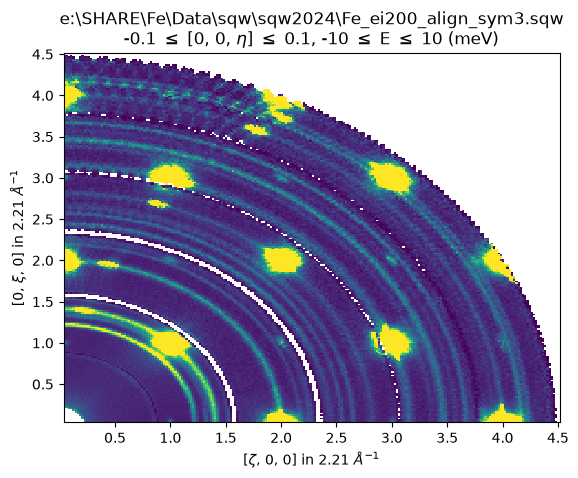

In [5]:
w2.plot()
lz(0,10)

In [6]:

lp = line_proj([-1,1,0],[1,1,0],'offset',[1,1,0])
w2 = cut(w4,lp,[0.02],[-0.1,0.1],[-0.1,0.1],2)

*** Step   1 of   3; Read data for 10000000 pixels -- processing data... ----->  retained   5013248 pixels
*** Step   2 of   3; Read data for 10000000 pixels -- processing data... ----->  retained   5219756 pixels
*** Step   3 of   3; Read data for  4696947 pixels -- processing data... ----->  retained   2160221 pixels
*** Cut timings: Total=20.602s | Read speed: 118.31 MB/sec
    Resulting pix preparation:  28.9%


(0.0, 1.0)

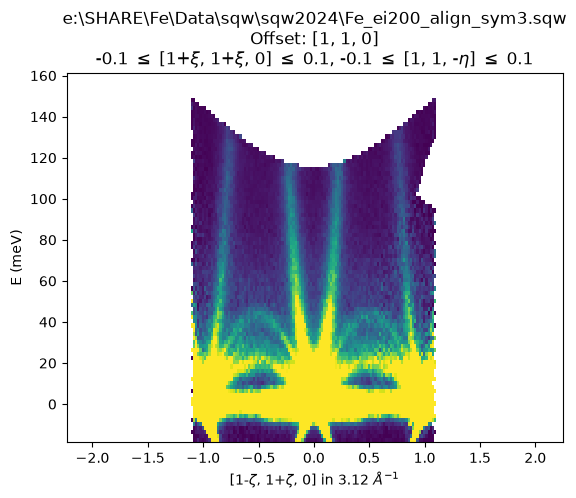

In [7]:
w2.plot()
lz(0,1)

In [8]:
from pyhorace.coord_transf.symop import *
w2s = cut(w2,lp,[0,0.02,1],[-0.1,0.1],[-0.1,0.1],2,SymopReflection('normvec',[-1,1,0],'offset',[1,1,0]))

*** Step   1 of   2; Read data for 10000000 pixels -- processing data... ----->  retained   9986267 pixels
*** Step   2 of   2; Read data for  2208550 pixels -- processing data... ----->  retained   2187220 pixels
*** Cut timings: Total=16.221s | Access speed: 251.77 MB/sec
    Resulting pix preparation:  31.0%


(0.0, 1.0)

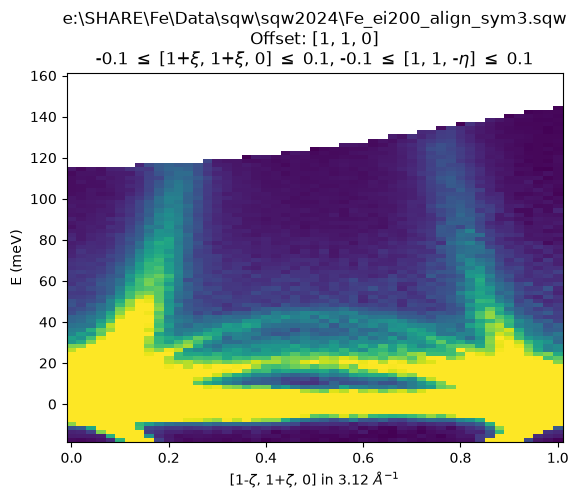

In [9]:
w2s.plot()
lz(0,1)

In [18]:
w1 = cut(w2s,[],[60,70])

*** Step   1 of   1; Read data for   828970 pixels -- processing data... ----->  retained    690244 pixels
*** Cut timings: Total=0.822s | Access speed: 177.93 MB/sec
    Resulting pix preparation:  38.4%


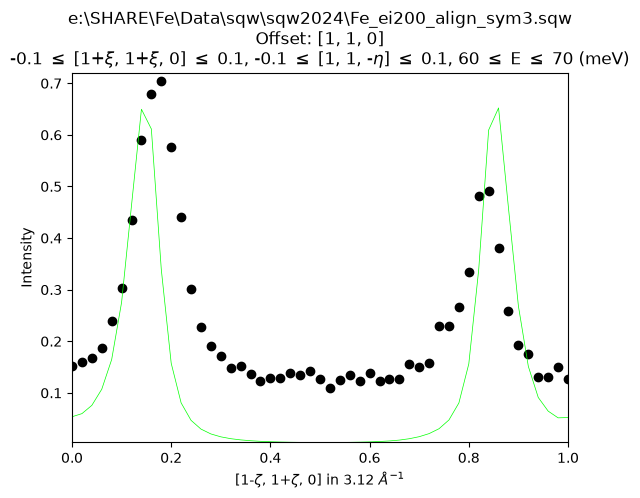

In [21]:
from pyhorace.models import *
import numpy as np
#init_fg_params = [coffect_ff,T,gamma,Seff, gap, J0, J1, J2, J3, J4];
#init_fg_params = [T,gamma,Seff, gap, J0, J1, J2, J3, J4];
acolor('k')
w1.plot()
in_par = np.array([8,20,100,0,35])
acolor('g')
w1_eval = w1.sqw_eval(sqw_bcc_hfm,in_par)
w1_eval.pl();